# DATA 266 — Homework 3
## Prompt Engineering (LangChain) & Self-Attention with Causal Masking from Scratch

**Name:** Rohil Utture  **·  SID4:** 2708

This notebook has two parts:

1. **Prompt Engineering (5 marks)** — Zero-Shot, Few-Shot, Chain-of-Thought, Zero-Shot CoT,
   Meta-Prompting, and Tree of Thoughts, each with **two** worked examples, called
   programmatically through **LangChain** (no chat-history screenshots).
2. **Self-Attention + Causal Masking (10 marks)** — single-head scaled dot-product
   self-attention implemented from scratch in PyTorch, trained with a next-token objective,
   visualized **unmasked** (Part 1) and **causal-masked** (Part 2).

> **Section 0 note.** Per Assignment 1's Section 0, every seed is set from `SID4` (`SEED = 2708`).
> The Section 0 requirement to also build a second hyperparameter-modified model is **waived** for
> this assignment — the *unmasked* and *masked* attention networks are the two trained models.


## Section 0 — Reproducibility parameters

In [1]:
import random, numpy as np

SID4 = 2708
SEED = SID4          # torch / numpy / random seed (Section 0.1)
print(f"SID4={SID4}  SEED={SEED}")

random.seed(SEED)
np.random.seed(SEED)
# torch seed is set again in Part 2 right before model construction

SID4=2708  SEED=2708


A tiny setup: install the packages (run once), then configure one chat model that every technique reuses. The default is a **local Ollama** model (`llama3.1`, `temperature=0` for reproducibility) — no API key needed; just have the Ollama server running and `ollama pull llama3.1` done first. Swap the commented lines for OpenAI or Anthropic if you prefer — the rest of the notebook is unchanged because every chain depends only on the `llm` object.

In [2]:
# Run once if needed:
# %pip install -q langchain langchain-core langchain-ollama


In [3]:
from langchain_ollama import ChatOllama
# --- alternatives (uncomment one; install the matching package) ---
# from langchain_openai import ChatOpenAI
# from langchain_anthropic import ChatAnthropic

MODEL_NAME = "llama3.1"          # run `ollama pull llama3.1` in a terminal first
llm = ChatOllama(model=MODEL_NAME, temperature=0)
# llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)                 # needs OPENAI_API_KEY
# llm = ChatAnthropic(model="claude-3-5-haiku-latest", temperature=0)  # needs ANTHROPIC_API_KEY

# quick connection check with a friendly hint if Ollama isn't reachable
try:
    llm.invoke("ping")
    print("LLM configured and reachable:", MODEL_NAME)
except Exception as e:
    print("Could not reach Ollama:", type(e).__name__)
    print("Checklist: (1) is the Ollama app/server running?  "
          f"(2) did you run `ollama pull {MODEL_NAME}`?")


LLM configured and reachable: llama3.1


A tiny helper runs a chain and prints the result. It fails gracefully if no API key is
set, so the notebook still executes top-to-bottom; with a key set, it prints the real model
output.

In [4]:
from langchain_core.output_parsers import StrOutputParser

def run(title, prompt, variables):
    """Build prompt | llm | parser, invoke, and pretty-print the output."""
    chain = prompt | llm | StrOutputParser()
    print("=" * 70)
    print(title)
    print("-" * 70)
    print("PROMPT SENT:\n" + prompt.format(**variables))
    print("-" * 70)
    try:
        out = chain.invoke(variables)
        print("MODEL OUTPUT:\n" + out)
    except Exception as e:
        print(f"[skipped — no reachable LLM/API key: {type(e).__name__}]")
    print("=" * 70 + "\n")

### 1.1 — Zero-Shot Prompting
The model is asked to solve a task directly, with **no examples** and no reasoning scaffold.
It relies entirely on knowledge baked in during pre-training.


In [5]:
from langchain_core.prompts import PromptTemplate

# Example A — arithmetic
zs_math = PromptTemplate.from_template("Question: {q}\nAnswer:")
run("ZERO-SHOT · Example A (arithmetic)", zs_math, {"q": "What is 17 * 24?"})

# Example B — text sentiment classification
zs_text = PromptTemplate.from_template(
    "Classify the sentiment of the review as Positive, Negative, or Neutral.\n"
    "Review: {review}\nSentiment:")
run("ZERO-SHOT · Example B (sentiment)", zs_text,
    {"review": "The battery dies in an hour and support never replied."})

ZERO-SHOT · Example A (arithmetic)
----------------------------------------------------------------------
PROMPT SENT:
Question: What is 17 * 24?
Answer:
----------------------------------------------------------------------
MODEL OUTPUT:
17 * 24 = 408

ZERO-SHOT · Example B (sentiment)
----------------------------------------------------------------------
PROMPT SENT:
Classify the sentiment of the review as Positive, Negative, or Neutral.
Review: The battery dies in an hour and support never replied.
Sentiment:
----------------------------------------------------------------------
MODEL OUTPUT:
Negative.



### 1.2 — Few-Shot Prompting
A handful of **input→output exemplars** are placed in the prompt so the model infers the
task format and pattern before answering the new query.


In [6]:
from langchain_core.prompts import FewShotPromptTemplate

# Example A — word-problem pattern via FewShotPromptTemplate
ex_prompt = PromptTemplate.from_template("Q: {question}\nA: {answer}")
math_examples = [
    {"question": "A pen costs $3. How much do 4 pens cost?", "answer": "$12"},
    {"question": "A book costs $7. How much do 3 books cost?", "answer": "$21"},
]
fs_math = FewShotPromptTemplate(
    examples=math_examples, example_prompt=ex_prompt,
    suffix="Q: {question}\nA:", input_variables=["question"])
run("FEW-SHOT · Example A (word problems)", fs_math,
    {"question": "A ticket costs $9. How much do 6 tickets cost?"})

# Example B — entity/format extraction learned from examples
extract_examples = [
    {"question": "Book a flight to Tokyo on May 3.", "answer": "city: Tokyo, date: May 3"},
    {"question": "Fly me to Paris on June 12.",       "answer": "city: Paris, date: June 12"},
]
fs_extract = FewShotPromptTemplate(
    examples=extract_examples, example_prompt=ex_prompt,
    suffix="Q: {question}\nA:", input_variables=["question"])
run("FEW-SHOT · Example B (structured extraction)", fs_extract,
    {"question": "Get me to Berlin on August 21."})

FEW-SHOT · Example A (word problems)
----------------------------------------------------------------------
PROMPT SENT:
Q: A pen costs $3. How much do 4 pens cost?
A: $12

Q: A book costs $7. How much do 3 books cost?
A: $21

Q: A ticket costs $9. How much do 6 tickets cost?
A:
----------------------------------------------------------------------
MODEL OUTPUT:
To find the cost of 6 tickets, multiply the cost of 1 ticket by 6:

$9 x 6 = $54

The answer is $54.

FEW-SHOT · Example B (structured extraction)
----------------------------------------------------------------------
PROMPT SENT:
Q: Book a flight to Tokyo on May 3.
A: city: Tokyo, date: May 3

Q: Fly me to Paris on June 12.
A: city: Paris, date: June 12

Q: Get me to Berlin on August 21.
A:
----------------------------------------------------------------------
MODEL OUTPUT:
city: Berlin, date: August 21



### 1.3 — Chain-of-Thought (CoT) Prompting
Each exemplar shows the **worked reasoning**, not just the final answer, so the model imitates
step-by-step thinking on the new problem. (This is *few-shot CoT*: reasoning is demonstrated.)


In [7]:
# Example A — multi-step arithmetic word problem with a reasoned exemplar
cot_math = PromptTemplate.from_template(
    "Q: {ex_q}\nA: {ex_reason}\n\nQ: {q}\nA:")
run("CHAIN-OF-THOUGHT · Example A (arithmetic reasoning)", cot_math, {
    "ex_q": "Roger has 5 balls. He buys 2 cans of 3 balls each. How many now?",
    "ex_reason": ("Start with 5. Two cans of 3 balls = 2 x 3 = 6. "
                  "Total = 5 + 6 = 11. The answer is 11."),
    "q": "A cafe had 23 muffins. It sold 17 and baked 14 more. How many now?",
})

# Example B — logical/syllogistic reasoning with a reasoned exemplar
cot_logic = PromptTemplate.from_template(
    "Q: {ex_q}\nA: {ex_reason}\n\nQ: {q}\nA:")
run("CHAIN-OF-THOUGHT · Example B (logic)", cot_logic, {
    "ex_q": "All cats are mammals. All mammals are animals. Are cats animals?",
    "ex_reason": ("Cats are a subset of mammals, and mammals are a subset of animals, "
                  "so by transitivity cats are animals. The answer is Yes."),
    "q": "All roses are flowers. Some flowers fade quickly. Do all roses fade quickly?",
})

CHAIN-OF-THOUGHT · Example A (arithmetic reasoning)
----------------------------------------------------------------------
PROMPT SENT:
Q: Roger has 5 balls. He buys 2 cans of 3 balls each. How many now?
A: Start with 5. Two cans of 3 balls = 2 x 3 = 6. Total = 5 + 6 = 11. The answer is 11.

Q: A cafe had 23 muffins. It sold 17 and baked 14 more. How many now?
A:
----------------------------------------------------------------------
MODEL OUTPUT:
To find the current number of muffins, we need to subtract the number of muffins sold and add the number of muffins baked.

Start with 23 muffins.
Sold 17 muffins: 23 - 17 = 6
Baked 14 more muffins: 6 + 14 = 20

The answer is 20.

CHAIN-OF-THOUGHT · Example B (logic)
----------------------------------------------------------------------
PROMPT SENT:
Q: All cats are mammals. All mammals are animals. Are cats animals?
A: Cats are a subset of mammals, and mammals are a subset of animals, so by transitivity cats are animals. The answer is Yes.

Q:

### 1.4 — Zero-Shot Chain-of-Thought
No exemplars — instead the single trigger phrase **"Let's think step by step."** is appended,
which elicits reasoning from an instruction-tuned model (Kojima et al., 2022).


In [8]:
# Example A — the classic "bat and ball" trap
zscot_a = PromptTemplate.from_template("Q: {q}\nA: Let's think step by step.")
run("ZERO-SHOT CoT · Example A (bat & ball)", zscot_a,
    {"q": "A bat and a ball cost $1.10 in total. The bat costs $1.00 more "
          "than the ball. How much does the ball cost?"})

# Example B — multi-hop counting/date reasoning
zscot_b = PromptTemplate.from_template("Q: {q}\nA: Let's think step by step.")
run("ZERO-SHOT CoT · Example B (multi-hop)", zscot_b,
    {"q": "If today is Wednesday, what day of the week will it be 100 days from now?"})

ZERO-SHOT CoT · Example A (bat & ball)
----------------------------------------------------------------------
PROMPT SENT:
Q: A bat and a ball cost $1.10 in total. The bat costs $1.00 more than the ball. How much does the ball cost?
A: Let's think step by step.
----------------------------------------------------------------------
MODEL OUTPUT:
To solve this problem, let's break it down step by step.

## Step 1: Define the variables
Let's denote the cost of the ball as B and the cost of the bat as T.

## Step 2: Translate the given information into equations
We know that the total cost of the bat and the ball is $1.10, so we can write the equation: B + T = 1.10.
We also know that the bat costs $1.00 more than the ball, so we can write the equation: T = B + 1.00.

## Step 3: Substitute the second equation into the first equation
We can substitute T = B + 1.00 into the first equation: B + (B + 1.00) = 1.10.

## Step 4: Simplify the equation
Combine like terms: 2B + 1.00 = 1.10.

## Step 

### 1.5 — Meta-Prompting
The model is asked to **reason about the prompt itself** — first design/critique an optimal
strategy for the task, then apply it. The prompt operates one level up: it prompts *about
prompting*.


In [9]:
from langchain_core.prompts import ChatPromptTemplate

# Example A — model designs its own solving strategy, then solves
meta_a = ChatPromptTemplate.from_messages([
    ("system",
     "You are an expert problem-solving strategist. For any task, FIRST write the ideal "
     "step-by-step method to solve it, THEN execute that method to give the final answer."),
    ("user", "{q}"),
])
run("META-PROMPTING · Example A (self-designed method)", meta_a,
    {"q": "A train travels 60 km in 45 minutes. What is its speed in km/h?"})

# Example B — model writes the optimal prompt for a writing task, then answers it
meta_b = ChatPromptTemplate.from_messages([
    ("system",
     "You are a prompt engineer. Given a user goal, FIRST write the best possible prompt "
     "(with role, constraints, and output format) to achieve it, THEN answer using that prompt."),
    ("user", "Goal: {goal}"),
])
run("META-PROMPTING · Example B (prompt-for-a-prompt)", meta_b,
    {"goal": "Summarize the causes of the water cycle for a 10-year-old in 3 bullet points."})

META-PROMPTING · Example A (self-designed method)
----------------------------------------------------------------------
PROMPT SENT:
System: You are an expert problem-solving strategist. For any task, FIRST write the ideal step-by-step method to solve it, THEN execute that method to give the final answer.
Human: A train travels 60 km in 45 minutes. What is its speed in km/h?
----------------------------------------------------------------------
MODEL OUTPUT:
**Ideal Step-by-Step Method:**

1. Convert the time from minutes to hours.
2. Use the formula: Speed = Distance / Time
3. Plug in the values for distance and time to calculate the speed.

**Execution:**

1. Convert 45 minutes to hours: 45 minutes = 45/60 = 0.75 hours
2. Use the formula: Speed = Distance / Time
3. Plug in the values: Speed = 60 km / 0.75 hours
4. Calculate the speed: Speed = 80 km/h

**Final Answer:** The speed of the train is 80 km/h.

META-PROMPTING · Example B (prompt-for-a-prompt)
------------------------------

### 1.6 — Tree of Thoughts (ToT)
The model explores **multiple reasoning branches**, evaluates/critiques them, and keeps the
best — approximated here with a single prompt that instantiates several "experts" who reason
in parallel, critique each other, and converge (Yao et al., 2023).


In [10]:
# Example A — deductive logic puzzle explored by multiple experts
tot_a = PromptTemplate.from_template(
    "Imagine {n} independent experts solving the problem below.\n"
    "Each expert writes their first reasoning step, then they compare steps and discard any "
    "that are flawed. They continue expanding only the promising line of reasoning until they "
    "agree on a single answer. Show the branches, the critique, and the final answer.\n\n"
    "Problem: {q}")
run("TREE-OF-THOUGHTS · Example A (logic puzzle)", tot_a, {
    "n": 3,
    "q": ("Anna, Ben and Carla each have a different pet: cat, dog, fish. "
          "Anna does not have the dog. Ben has the fish. Who has the cat?"),
})

# Example B — constrained arithmetic search (Game-of-24 style)
tot_b = PromptTemplate.from_template(
    "Use Tree-of-Thoughts: propose {n} candidate first moves, evaluate each as "
    "'sure / maybe / impossible' toward the goal, then fully expand only the best candidate.\n\n"
    "Goal: use the numbers {nums} exactly once with + - x / to make 24. Show the search.")
run("TREE-OF-THOUGHTS · Example B (Game of 24)", tot_b,
    {"n": 3, "nums": "4, 4, 6, 8"})

TREE-OF-THOUGHTS · Example A (logic puzzle)
----------------------------------------------------------------------
PROMPT SENT:
Imagine 3 independent experts solving the problem below.
Each expert writes their first reasoning step, then they compare steps and discard any that are flawed. They continue expanding only the promising line of reasoning until they agree on a single answer. Show the branches, the critique, and the final answer.

Problem: Anna, Ben and Carla each have a different pet: cat, dog, fish. Anna does not have the dog. Ben has the fish. Who has the cat?
----------------------------------------------------------------------
MODEL OUTPUT:
**Expert 1: Dr. Smith**

1. Anna does not have the dog.
2. Ben has the fish.
3. Since Ben has the fish, he cannot have the cat (because the fish and cat are two different pets).
4. Anna does not have the dog, so she must have the cat.

**Expert 2: Dr. Lee**

1. Ben has the fish.
2. Anna does not have the dog.
3. Since Ben has the fish,

### 1.7 — Comparison of techniques (fill in after running)

| Technique | What it adds | Best on the examples above |
|---|---|---|
| Zero-Shot | nothing extra | easy, single-step tasks |
| Few-Shot | format/pattern exemplars | tasks needing a fixed output shape |
| Chain-of-Thought | demonstrated reasoning | multi-step math / logic |
| Zero-Shot CoT | a reasoning *trigger* only | the bat-&-ball trap (fixes the $0.10 error) |
| Meta-Prompting | reasoning about the method | ambiguous / open tasks |
| Tree of Thoughts | branch + critique + prune | search / puzzle problems |

Detailed findings (which technique fixed which failure, token cost, etc.) are written up in the
accompanying **findings PDF**.


---
# Part 2 — Self-Attention & Causal Masking from Scratch (10 marks)

Single-head **scaled dot-product self-attention** implemented from scratch following
Section 3.2 of *Attention Is All You Need*:

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

**Constraints honoured:** no `nn.MultiheadAttention`, no `nn.Transformer`, no HuggingFace.
Only `nn.Embedding`, `nn.Linear`, matmul, softmax and cross-entropy are used.


## 2.1 — Dataset and word-level tokenization
The required text is used verbatim. Tokenization is word-level: lowercase, drop periods, split
on whitespace. Repeated words (*models*, *of*, *on*, *attention*) share one embedding, which
makes the learned attention patterns more interesting to read.


In [11]:
import re, math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

TEXT = (
    "Neural networks are powerful models for learning representations from data. "
    "They consist of layers of interconnected neurons. "
    "Attention mechanisms allow models to focus on relevant parts of the input. "
    "Transformers rely entirely on attention instead of recurrence. "
    "Autoregressive models generate text one token at a time."
)

tokens = re.sub(r"[.]", " ", TEXT.lower()).split()   # word-level tokens
vocab  = sorted(set(tokens))
stoi   = {w: i for i, w in enumerate(vocab)}
itos   = {i: w for w, i in stoi.items()}
ids    = torch.tensor([stoi[w] for w in tokens], dtype=torch.long)
T, Vsz = len(tokens), len(vocab)
print(f"sequence length T = {T} tokens, vocabulary size = {Vsz}")
print("tokens:", tokens)

sequence length T = 46 tokens, vocabulary size = 39
tokens: ['neural', 'networks', 'are', 'powerful', 'models', 'for', 'learning', 'representations', 'from', 'data', 'they', 'consist', 'of', 'layers', 'of', 'interconnected', 'neurons', 'attention', 'mechanisms', 'allow', 'models', 'to', 'focus', 'on', 'relevant', 'parts', 'of', 'the', 'input', 'transformers', 'rely', 'entirely', 'on', 'attention', 'instead', 'of', 'recurrence', 'autoregressive', 'models', 'generate', 'text', 'one', 'token', 'at', 'a', 'time']


## 2.2 — Trainable embedding layer
An `nn.Embedding` maps each token id to a learned `d_model`-dimensional vector. A learned
**positional** embedding is added so the permutation-invariant attention can use word order
(needed for a next-token objective).


In [12]:
D_MODEL = 64
torch.manual_seed(SEED)
demo_emb = nn.Embedding(Vsz, D_MODEL)
print("token embeddings for the first 4 tokens ->", demo_emb(ids[:4]).shape)  # [4, 64]

token embeddings for the first 4 tokens -> torch.Size([4, 64])


## 2.3 — Single-head scaled dot-product self-attention (from scratch)
`SelfAttentionLM` computes Q, K, V with three `nn.Linear` projections, scores
$QK^\top/\sqrt{d}$, applies softmax, and returns both the context and the **attention weight
matrix**. A `causal` flag adds the lower-triangular mask used in Part 2.2. A residual + small
feed-forward head turns the context into next-token logits.


In [13]:
class SelfAttentionLM(nn.Module):
    def __init__(self, vocab_size, seq_len, d_model=64, ffn=128, causal=False):
        super().__init__()
        self.causal, self.d_model = causal, d_model
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(seq_len, d_model)
        # Q, K, V, and output projections  (Section 3.2)
        self.Wq = nn.Linear(d_model, d_model, bias=False)
        self.Wk = nn.Linear(d_model, d_model, bias=False)
        self.Wv = nn.Linear(d_model, d_model, bias=False)
        self.Wo = nn.Linear(d_model, d_model, bias=False)
        # position-wise feed-forward (nn.Linear only)
        self.ff1 = nn.Linear(d_model, ffn)
        self.ff2 = nn.Linear(ffn, d_model)
        self.head = nn.Linear(d_model, vocab_size)   # next-token logits
        self.register_buffer("pos_idx", torch.arange(seq_len))

    def attention(self, x):
        Tq = x.size(0)
        Q, K, Vv = self.Wq(x), self.Wk(x), self.Wv(x)         # each [T, d]
        scores = (Q @ K.transpose(0, 1)) / math.sqrt(self.d_model)   # [T, T]
        if self.causal:                                       # Part 2.2 mask
            mask = torch.tril(torch.ones(Tq, Tq, device=x.device)).bool()
            scores = scores.masked_fill(~mask, float("-inf"))
        weights = torch.softmax(scores, dim=-1)               # [T, T]
        context = weights @ Vv                                # [T, d]
        return context, weights

    def forward(self, token_ids, return_attn=False):
        x = self.tok_emb(token_ids) + self.pos_emb(self.pos_idx[: token_ids.size(0)])
        context, weights = self.attention(x)
        x = x + self.Wo(context)                 # residual around attention
        x = x + self.ff2(F.relu(self.ff1(x)))    # residual around FFN
        logits = self.head(x)                    # [T, vocab]
        return (logits, weights) if return_attn else logits

## 2.4 — Train with a next-token (autoregressive) objective
Each position predicts the **next** token; cross-entropy is minimized so the embeddings and
the Q/K/V projections actually learn. Both models are seeded identically (`SEED = 2708`) so the
only difference between them is the causal mask.


In [14]:
def train_model(causal, epochs=700, lr=5e-3, tag=""):
    torch.manual_seed(SEED)                       # identical initialization
    model = SelfAttentionLM(Vsz, T, d_model=D_MODEL, causal=causal)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    inp, tgt = ids[:-1], ids[1:]                  # (token_t -> token_{t+1})
    for ep in range(epochs):
        model.train()
        loss = F.cross_entropy(model(inp), tgt)
        opt.zero_grad(); loss.backward(); opt.step()
        if (ep + 1) % 100 == 0:
            print(f"[{tag}] epoch {ep+1:4d}  loss {loss.item():.4f}")
    model.eval()
    with torch.no_grad():
        _, W = model(ids, return_attn=True)       # attention over the FULL sequence
    return model, W.cpu().numpy()

def plot_attention(W, title):
    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(W, cmap="viridis", aspect="auto")
    ax.set_xticks(range(T)); ax.set_yticks(range(T))
    ax.set_xticklabels(tokens, rotation=90, fontsize=6)
    ax.set_yticklabels(tokens, fontsize=6)
    ax.set_xlabel("Key position (token being attended to)")
    ax.set_ylabel("Query position (current token)")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="attention weight")
    plt.tight_layout(); plt.show()

## 2.5 — Unmasked model: train, then visualize
This is the Part 1 deliverable: full (bidirectional) self-attention. After training, the
attention weights are non-uniform and structured — they reflect **learned** patterns, not the
random initialization.


[unmasked] epoch  100  loss 0.0000
[unmasked] epoch  200  loss 0.0000
[unmasked] epoch  300  loss 0.0000
[unmasked] epoch  400  loss 0.0000
[unmasked] epoch  500  loss 0.0000
[unmasked] epoch  600  loss 0.0000
[unmasked] epoch  700  loss 0.0000
attention matrix shape: (46, 46)


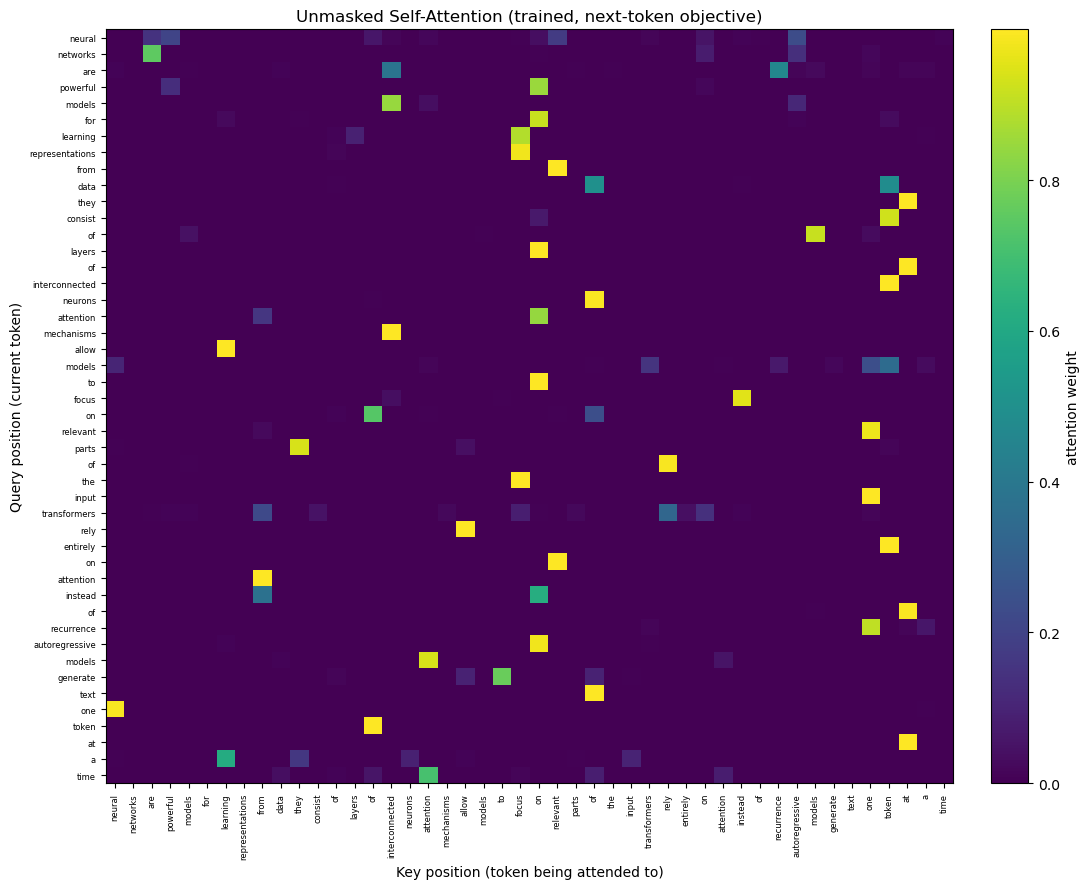

[unmasked] epoch  500  loss 0.0000
[unmasked] epoch  600  loss 0.0000


[unmasked] epoch  700  loss 0.0000
attention matrix shape: (46, 46)


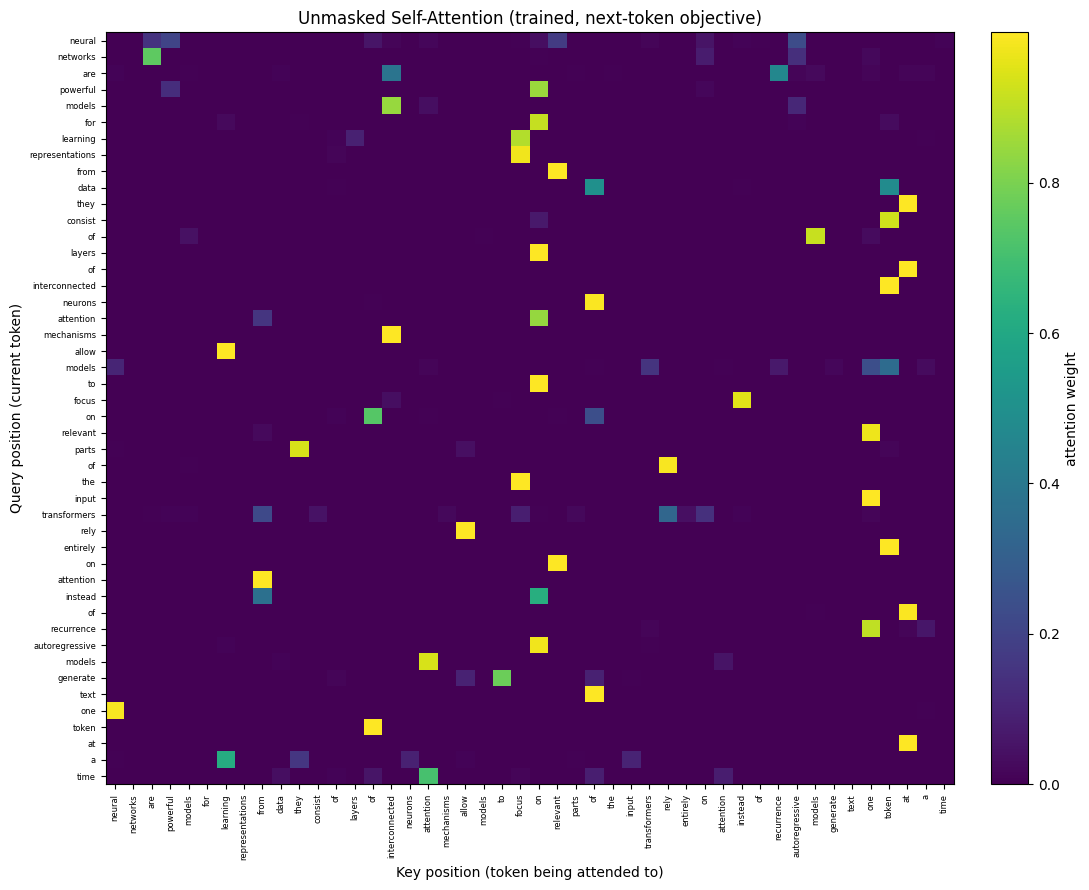

In [15]:
model_unmasked, W_unmasked = train_model(causal=False, tag="unmasked")
print("attention matrix shape:", W_unmasked.shape)   # [T, T]
plot_attention(W_unmasked, "Unmasked Self-Attention (trained, next-token objective)")

## 2.6 — Part 2.2: add the causal mask, train, and visualize
A lower-triangular mask sets every future score to $-\infty$ **before softmax**, so each token
can attend only to itself and earlier tokens. The resulting heatmap is lower-triangular: the
entire upper triangle is exactly zero.


[masked] epoch  100  loss 0.0000
[masked] epoch  200  loss 0.0000
[masked] epoch  300  loss 0.0000
[masked] epoch  400  loss 0.0000
[masked] epoch  500  loss 0.0000
[masked] epoch  600  loss 0.0000
[masked] epoch  700  loss 0.0000
masked: max weight in the upper triangle (future) = 0.0   -> should be 0.0
masked: each row sums to 1? True
unmasked: future weights in row 0 that are non-zero = 35 (bidirectional, so > 0)


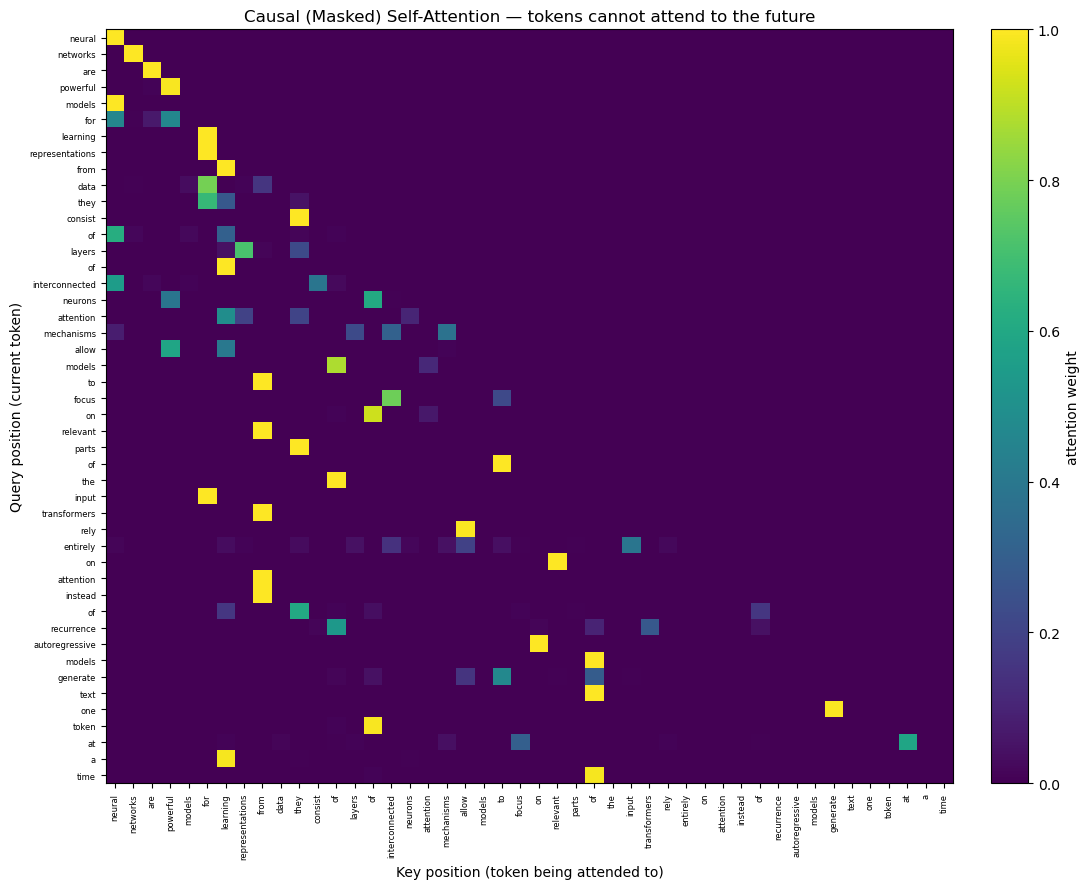

[masked] epoch  500  loss 0.0000
[masked] epoch  600  loss 0.0000


[masked] epoch  700  loss 0.0000
masked: max weight in the upper triangle (future) = 0.0   -> should be 0.0
masked: each row sums to 1? True
unmasked: future weights in row 0 that are non-zero = 35 (bidirectional, so > 0)


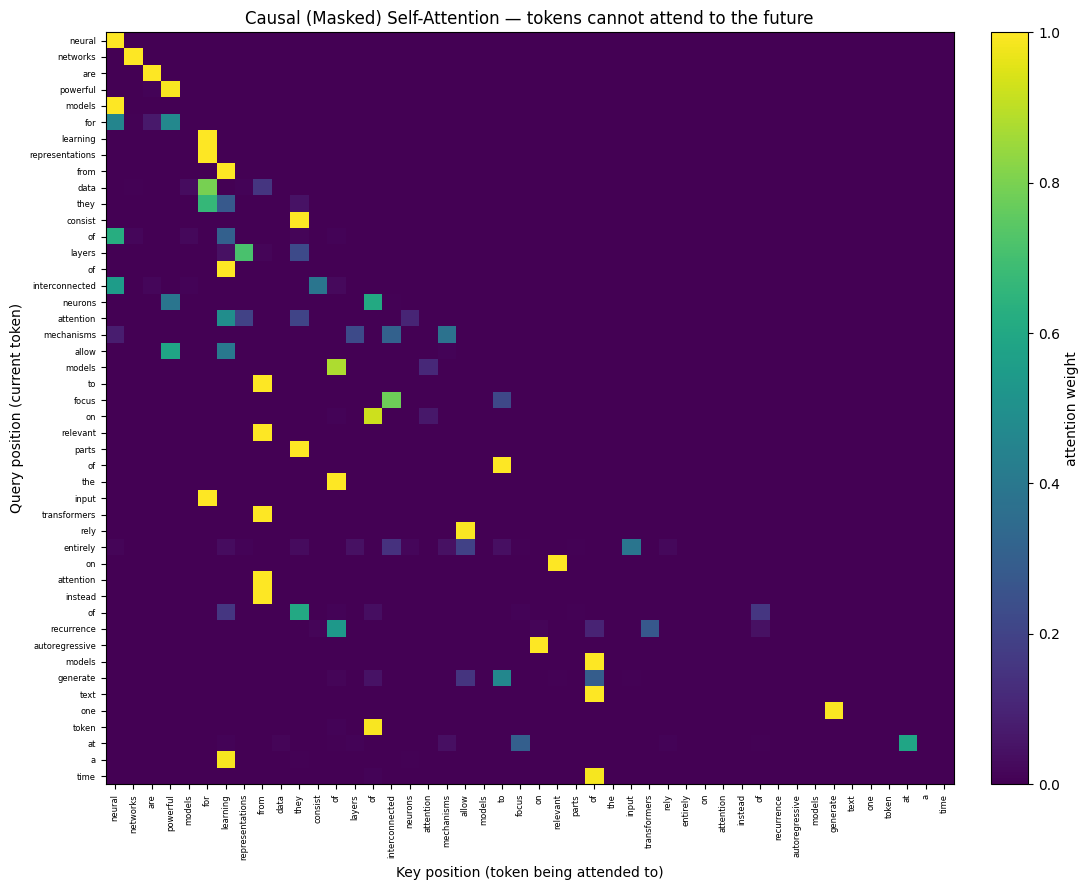

In [16]:
model_masked, W_masked = train_model(causal=True, tag="masked")

# --- sanity checks -------------------------------------------------
import numpy as np
upper = np.triu(W_masked, k=1)
print("masked: max weight in the upper triangle (future) =", round(float(upper.max()), 8),
      "  -> should be 0.0")
print("masked: each row sums to 1?", np.allclose(W_masked.sum(1), 1.0))
print("unmasked: future weights in row 0 that are non-zero =",
      int((W_unmasked[0, 1:] > 1e-4).sum()), "(bidirectional, so > 0)")

plot_attention(W_masked, "Causal (Masked) Self-Attention — tokens cannot attend to the future")

## 2.7 — What the two heatmaps show

* **Unmasked** — attention is spread across the whole square, including positions *above* the
  diagonal, i.e. tokens attend to **future** words. The bright cells are sharp and specific,
  confirming the pattern was learned during training rather than left at initialization.
* **Masked** — every cell above the diagonal is zero; attention is confined to the
  lower triangle. Position 0 attends only to itself, and each later token distributes its
  attention over itself and earlier tokens only. This is exactly the decoder self-attention
  behaviour required for autoregressive generation.

Loss reaches ≈0 quickly because the dataset is a single short sequence that the network
memorizes; that is expected here and does not affect the point of the exercise, which is to
**visualize learned attention structure** and the effect of causal masking. A fuller written
discussion is in the findings PDF.
